# Generate Figures

Generate figures visualising:

1. Raw data and text annotations
2. 2D PCA of X_text and X_joint

PCA is always fit on train only and applied to val without refitting.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import textwrap

import sys, os
sys.path.insert(0, os.path.abspath(".."))  # points to mmtt-bench/

from src.mmtt_bench.data import build_category_data, load_split
from src.mmtt_bench.tokenizers import TEXT_TOKENIZERS, TS_TOKENIZERS
from src.mmtt_bench.viz import CAT_COLORS, plot_2d_embeddings
from src.mmtt_bench.data import load_split, build_category_data

## Load MMTT-Bench

In [14]:
TRAIN_PATH = "../datasets/benchmark_splits/train.json"
VAL_PATH   = "../datasets/benchmark_splits/val.json"

In [ ]:
def load_category_data(data_path):
    raw      = load_split(data_path)
    text_tok = TEXT_TOKENIZERS['sentence_transformer']('sentence-transformers/all-distilroberta-v1')
    ts_tok   = TS_TOKENIZERS['identity'](lookback_steps=1)#['patch_mean'](patch_len=1, stride=2, lookback_steps=1).build()
    return build_category_data(
        raw,
        text_tokenizer = text_tok,
        ts_tokenizer   = ts_tok,
        horizon_steps  = 1,
        lookback_steps = 1,
        patch_len      = 1,
    )

train_data = load_category_data(TRAIN_PATH)
val_data   = load_category_data(VAL_PATH)
print("Train:", {k: len(v['y']) for k, v in train_data.items()})
print("Val:  ", {k: len(v['y']) for k, v in val_data.items()})

0.40390625
{'t': 18.8496, 'y': -0.5, 'dy': 1.0, 'phase': 'recover_from_constant', 'true_direction': 'increasing', 'true_magnitude': 'steep', 'category': 'correct', 'tense': 'future', 'samples': [{'text': 'The sine curve will shortly be observed to recover from negative 0.5.', 'template_idx': 9, 'tense': 'future', 'direction_word': 'recover', 'magnitude_word': '', 'irrelevant_group': None}]}


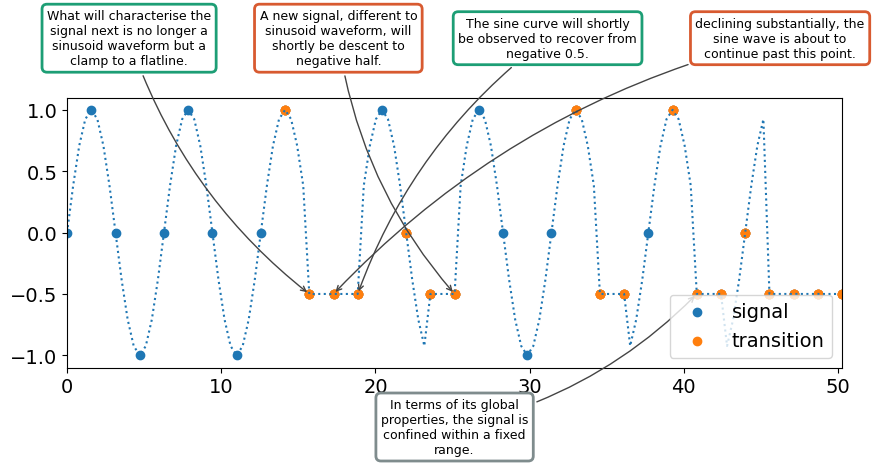

In [16]:
raw = load_split(TRAIN_PATH)
t_dense   = raw['metadata']['t']
y_dense   = raw['metadata']['y']
y_lookback = train_data['correct']['ts'][:,-1]
y_future = train_data['correct']['y'][:,0] #next lookback

fig, ax = plt.subplots(figsize=(10, 5))
x_sine = np.arange(0,50, np.pi/8)
y_sine = np.sin(x_sine)


mask = [t for t,y in zip(t_dense, y_dense) if y==-0.5]

new_mask = []
for i in range(len(mask)-1):
    if round(mask[i+1]- mask[i],2)== round(np.pi/2,2):
        new_mask.append(round(mask[i],2))
        new_mask.append(round(mask[i]+np.pi/8,2))
        new_mask.append(round(mask[i]+np.pi/4,2))
        new_mask.append(round(mask[i]+(np.pi*3)/8,2))
    else:
        new_mask.append(round(mask[i],2))

y_sine = [y if round(x,2) not in new_mask else -0.5 for x,y in zip(x_sine, y_sine)]

ax.plot(x_sine,y_sine, linestyle=':')
ax.scatter(t_dense, y_dense, label='signal')

transition = [pt for pt in raw['points'] if pt['phase'] in ['drop_to_constant', 'recover_from_constant']]
print(len(transition)/len(raw['points']))
ax.scatter([pt['t'] for pt in transition],[pt['y'] for pt in transition], label='transition')


def add_text_annotation(ax, annotation, category, text_pos, wrap_width=28):
    """text_pos: (x, y) in axes-fraction coords for the annotation box."""
    text = textwrap.fill(annotation['samples'][0]['text'], width=wrap_width)
    bbox_props = dict(boxstyle="round,pad=0.4", fc="white", ec=CAT_COLORS[category], lw=2)
    ax.annotate(
        text,
        xy=(annotation['t'], annotation['y']),   # arrow tip — data coords
        xycoords='data',
        xytext=text_pos,                          # box — axes fraction
        textcoords='axes fraction',
        bbox=bbox_props,
        arrowprops=dict(arrowstyle='->', color='#444',
                        connectionstyle='arc3,rad=0.15'),
        fontsize=9,
        va='center', ha='center',
    )


correct_annotation   = [pt for pt in raw['points'] if (pt['phase']=='drop_to_constant') and (pt['category']=='correct')][1]
incorrect_annotation = [pt for pt in raw['points'] if (pt['phase']=='recover_from_constant') and (pt['category']=='incorrect')][1]
add_text_annotation(ax, correct_annotation,   "correct",   text_pos=(0.08, 1.22))
add_text_annotation(ax, incorrect_annotation, "incorrect", text_pos=(0.35, 1.22))

correct_annotation   = [pt for pt in raw['points'] if (pt['phase']=='recover_from_constant') and (pt['category']=='correct')][0]
incorrect_annotation = [pt for pt in raw['points'] if (pt['phase']=='drop_to_constant') and (pt['category']=='incorrect')][2]
add_text_annotation(ax, correct_annotation,   "correct",   text_pos=(0.62, 1.22))
add_text_annotation(ax, incorrect_annotation, "incorrect", text_pos=(0.92, 1.22))

irrelevant_annotation = [pt for pt in raw['points'] if (pt['phase']=='drop_to_constant') and (pt['category']=='irrelevant')][8]
add_text_annotation(ax, irrelevant_annotation, "irrelevant", text_pos=(0.50, -0.22))

print(correct_annotation)

plt.xlim(0, 16*np.pi)
plt.subplots_adjust(top=0.72, bottom=0.18)
plt.legend()
plt.show()

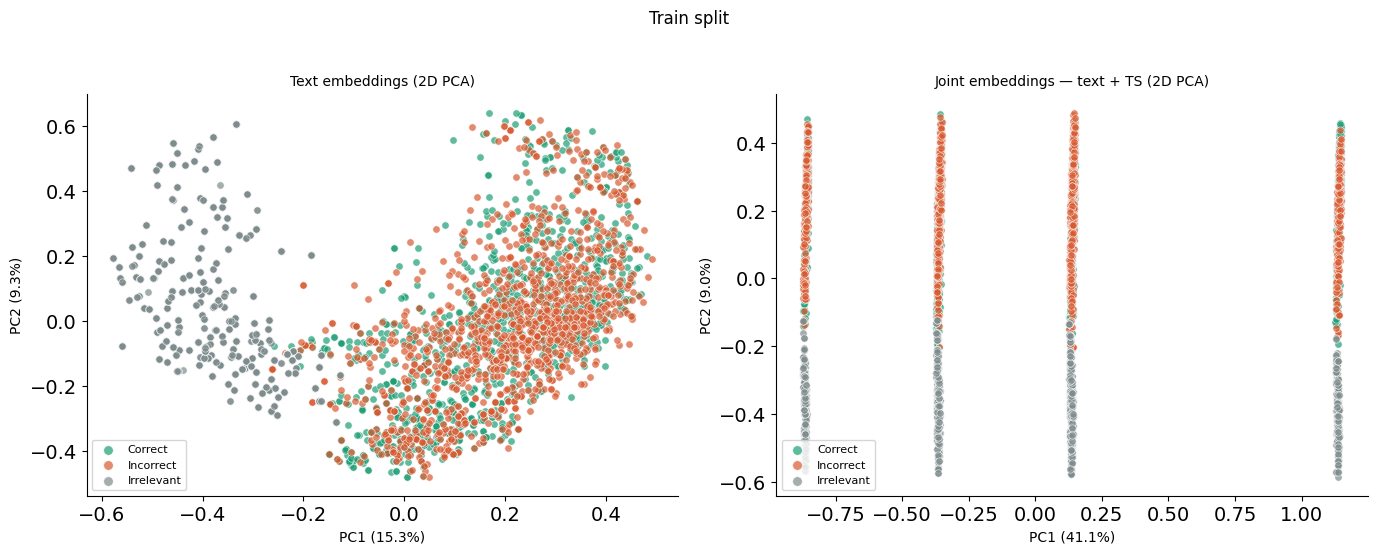

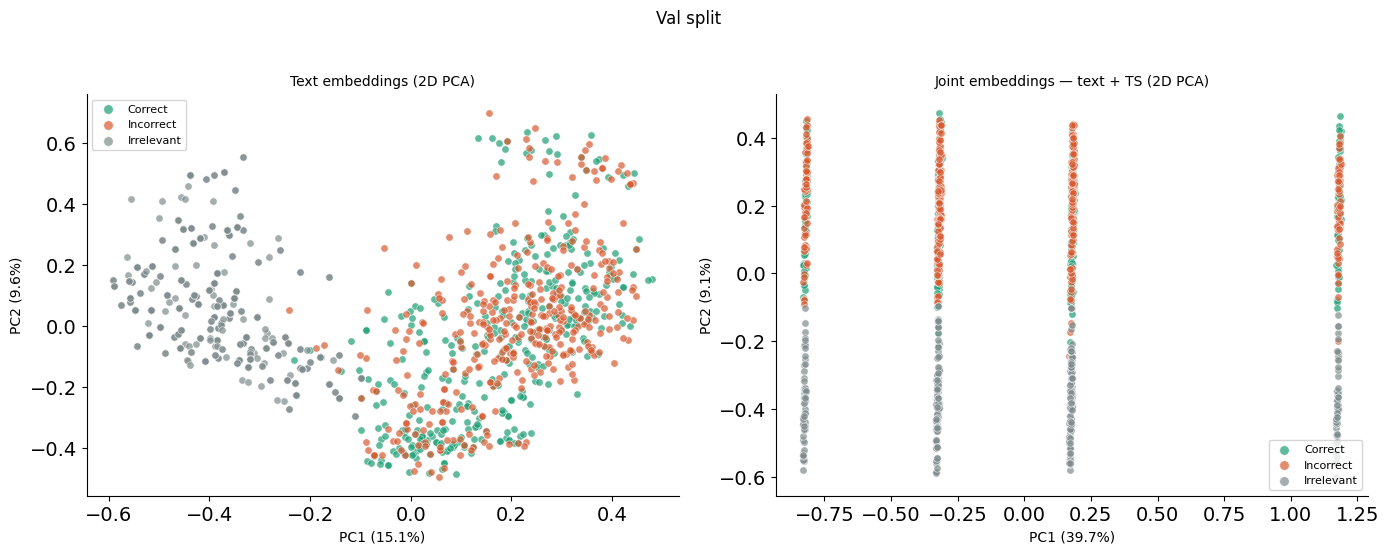

In [17]:
plot_2d_embeddings(train_data, val_data)